<a href="https://colab.research.google.com/github/HittersLab/jubilee-trp3-metocean-fatigue-analysis/blob/main/01_Metocean_EDA_Seasonal_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Case Exercise 1: Metocean EDA and Seasonal Analysis

### Question 1: Load and Inspect the Metocean Dataset

The objective of this question is to load the one-year hourly metocean dataset for the Jubilee TRP3 location and inspect its structure.

The dataset contains important environmental parameters, including significant wave height (Hs), peak wave period (Tp), wave direction, current speed, current direction, and wind speed.

The dataset will first be loaded into a Pandas DataFrame. We will then inspect the number of observations, column names, data types, missing values, duplicate records, and basic statistical information.

The timestamp column will be converted into a datetime format to support subsequent time-series and seasonal analysis.

**Data source:** Synthetic Jubilee TRP3 metocean dataset created for this educational case exercise. It is not actual field measurement data.

In [ ]:
# ============================================================
# CASE EXERCISE 1: METOCEAN EDA AND SEASONAL ANALYSIS
# QUESTION 1: LOAD AND INSPECT THE DATASET
# ============================================================

# Step 1: Import the required libraries

import pandas as pd
import numpy as np
from google.colab import files

# Step 2: Upload the metocean CSV dataset

uploaded = files.upload()

# Step 3: Read the uploaded CSV file

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# Step 4: Convert timestamp into datetime format

df["timestamp"] = pd.to_datetime(df["timestamp"])

# Step 5: Rename columns to consistent engineering names

df.rename(columns={
    "Hs_m": "hs_m",
    "Tp_s": "tp_s",
    "current_speed_ms": "current_ms",
    "wind_speed_ms": "wind_ms"
}, inplace=True)

# Step 6: Display the first five records

print("FIRST FIVE RECORDS")
display(df.head())

# Step 7: Check dataset dimensions

print("\nDATASET DIMENSIONS")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# Step 8: Inspect column names and data types

print("\nDATASET INFORMATION")
df.info()

# Step 9: Check for missing values

print("\nMISSING VALUES")
print(df.isnull().sum())

# Step 10: Check for duplicate records

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# Step 11: Generate descriptive statistics

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())

# Step 12: Check the time coverage

print("\nTIME COVERAGE")
print("Start date:", df["timestamp"].min())
print("End date:", df["timestamp"].max())

# Step 13: Check the number of unique timestamps

print("\nUNIQUE TIMESTAMPS")
print(df["timestamp"].nunique())

Saving jubilee_trp3_synthetic_metocean_1year.csv to jubilee_trp3_synthetic_metocean_1year.csv
FIRST FIVE RECORDS


,timestamp,hs_m,tp_s,wave_direction_deg,current_ms,current_direction_deg,wind_ms,wind_direction_deg
0,2025-01-01 00:00:00,1.151,9.506,253.8,0.460,190.5,3.711,233.9
1,2025-01-01 01:00:00,1.005,9.678,231.1,0.449,145.6,5.389,209.8
2,2025-01-01 02:00:00,1.308,9.942,179.3,0.484,134.7,4.649,249.9
3,2025-01-01 03:00:00,1.136,8.768,214.8,0.384,137.0,4.122,192.5
4,2025-01-01 04:00:00,1.222,7.180,174.9,0.462,159.9,7.837,214.7



DATASET DIMENSIONS
Number of rows: 8760
Number of columns: 8

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   timestamp              8760 non-null   datetime64[ns]
 1   hs_m                   8760 non-null   float64       
 2   tp_s                   8760 non-null   float64       
 3   wave_direction_deg     8760 non-null   float64       
 4   current_ms             8760 non-null   float64       
 5   current_direction_deg  8760 non-null   float64       
 6   wind_ms                8760 non-null   float64       
 7   wind_direction_deg     8760 non-null   float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 547.6 KB

MISSING VALUES
timestamp                0
hs_m                     0
tp_s                     0
wave_direction_deg       0
current_ms               0
current_d

,timestamp,hs_m,tp_s,wave_direction_deg,current_ms,current_direction_deg,wind_ms,wind_direction_deg
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,2025-07-02 11:30:00,1.430837,8.932695,225.933904,0.437771,145.059030,5.512968,210.410068
min,2025-01-01 00:00:00,0.403000,5.724000,104.300000,0.270000,19.800000,0.100000,2.900000
25%,2025-04-02 05:45:00,1.166000,8.312750,204.300000,0.378000,119.800000,4.451750,182.100000
50%,2025-07-02 11:30:00,1.378500,8.886500,225.400000,0.429000,145.300000,5.482500,210.500000
75%,2025-10-01 17:15:00,1.602250,9.484000,247.900000,0.483250,170.125000,6.598000,238.800000
max,2025-12-31 23:00:00,3.936000,13.834000,346.300000,1.040000,273.900000,12.054000,356.700000
std,NaN,0.426001,0.939776,32.011619,0.083846,34.661562,1.577789,41.193361



TIME COVERAGE
Start date: 2025-01-01 00:00:00
End date: 2025-12-31 23:00:00

UNIQUE TIMESTAMPS
8760


## Question 2: Comprehensive Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

Descriptive statistics will be used to understand the central tendency, variability and distribution of the metocean parameters. The analysis will include the mean, median, standard deviation, minimum, maximum, skewness and kurtosis.

### 2.2 Significant Wave Height Distribution

Significant wave height (Hs) will be examined using a Weibull probability distribution. The Weibull distribution is commonly used to represent wave-height variability in metocean analysis.

The distribution parameters will be estimated, and a Kolmogorov-Smirnov (KS) goodness-of-fit test will be performed.

### 2.3 Peak Wave Period Distribution

Peak wave period (Tp) will be examined using a log-normal distribution. The distribution parameters will be estimated, and the fitted distribution will be compared with the observed data.

### 2.4 Correlation Analysis

A correlation matrix will be generated to investigate relationships between significant wave height, peak wave period, current speed and wind speed.

Pearson correlation will be used to identify the strength and direction of linear relationships between these variables.

### 2.5 Time-Series and Seasonal Analysis

Time-series plots will be generated to examine changes in wave height, wave period, current speed and wind speed over the observation period.

Monthly statistics will also be calculated to investigate seasonal variation. The Gulf of Guinea seasonal context identifies November to March as the relatively calmer dry season and April to October as the more energetic wet/storm season.

The analysis will help identify patterns that may be relevant to subsea asset integrity and fatigue assessment.

Dataset shape: (8760, 8)

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
hs_m,8760.0,1.430837,0.426001,0.403,1.16600,1.3785,1.60225,3.936,1.861739,6.079522
tp_s,8760.0,8.932695,0.939776,5.724,8.31275,8.8865,9.48400,13.834,0.482417,1.010607
current_ms,8760.0,0.437771,0.083846,0.270,0.37800,0.4290,0.48325,1.040,0.912699,1.691949
wind_ms,8760.0,5.512968,1.577789,0.100,4.45175,5.4825,6.59800,12.054,0.040572,-0.090079



WEIBULL DISTRIBUTION RESULTS
Shape parameter: 3.2039
Location parameter: 0.0000
Scale parameter: 1.5846
KS statistic: 0.1187
KS p-value: 0.0000
Interpretation: The KS test indicates evidence against the Weibull fit at the 5% level.


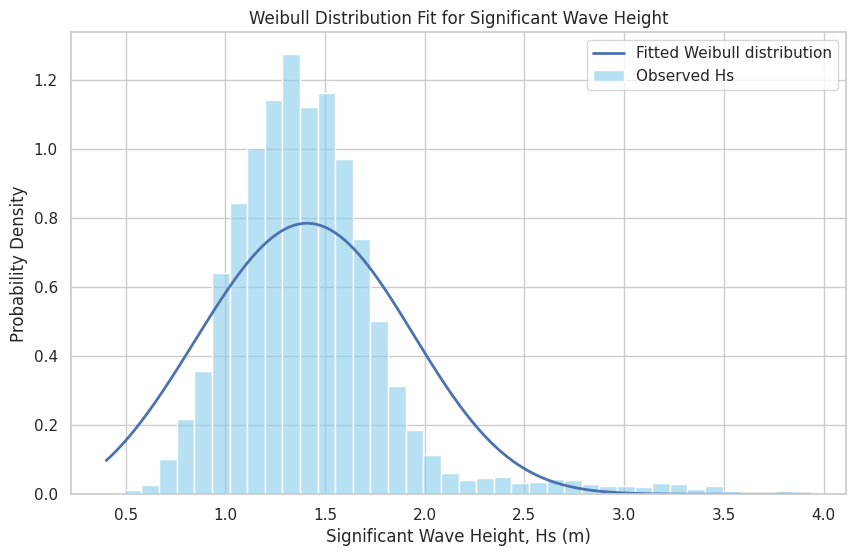


LOG-NORMAL DISTRIBUTION RESULTS
Shape parameter: 0.1043
Location parameter: 0.0000
Scale parameter: 8.8841
KS statistic: 0.0175
KS p-value: 0.0095
Interpretation: The KS test indicates evidence against the log-normal fit at the 5% level.


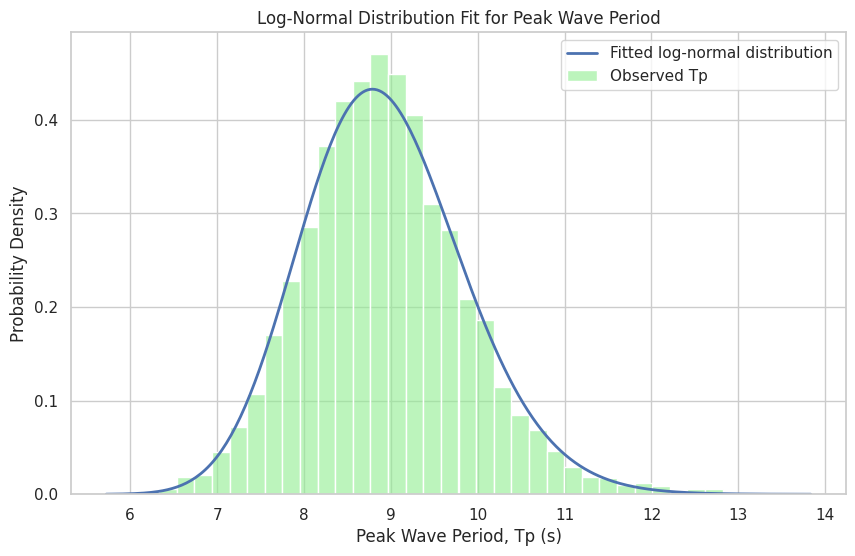


METOCEAN CORRELATION MATRIX


,hs_m,tp_s,current_ms,wind_ms
hs_m,1.000000,0.535748,0.117546,0.268299
tp_s,0.535748,1.000000,0.037006,0.092617
current_ms,0.117546,0.037006,1.000000,0.088172
wind_ms,0.268299,0.092617,0.088172,1.000000


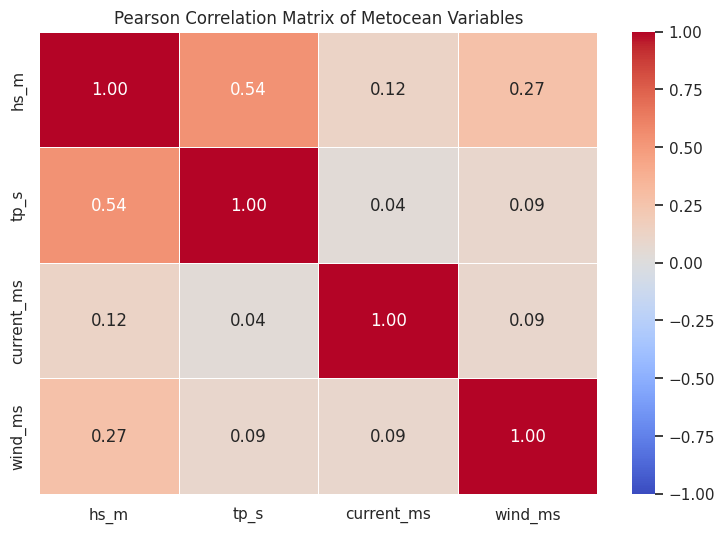

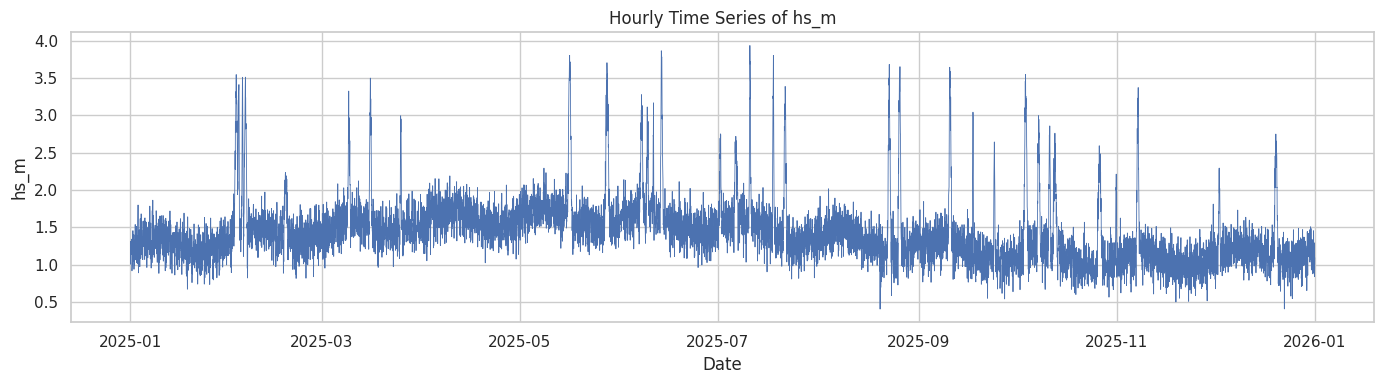

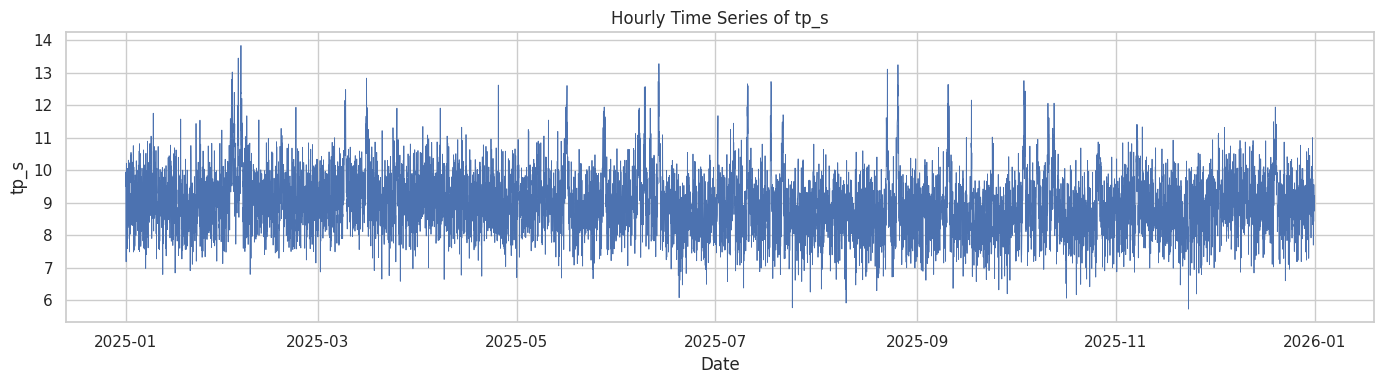

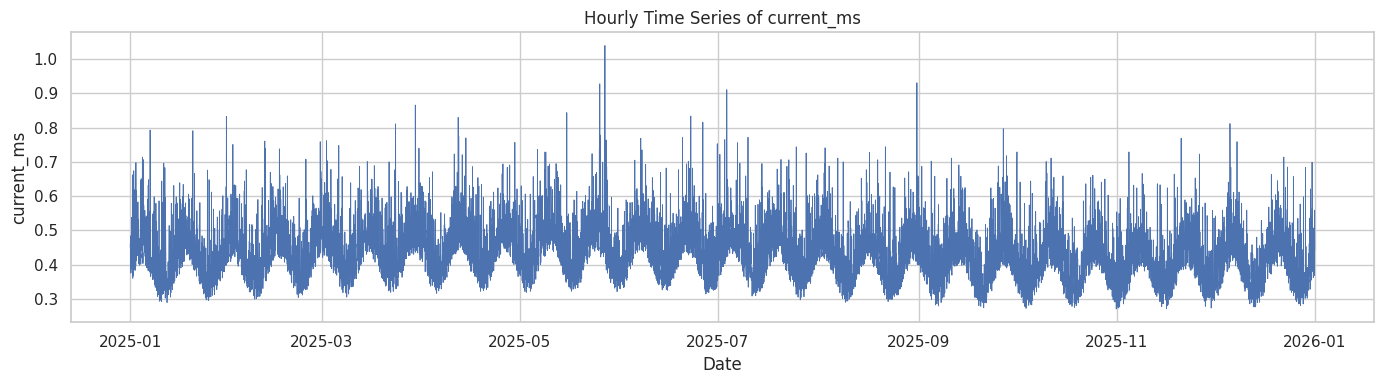

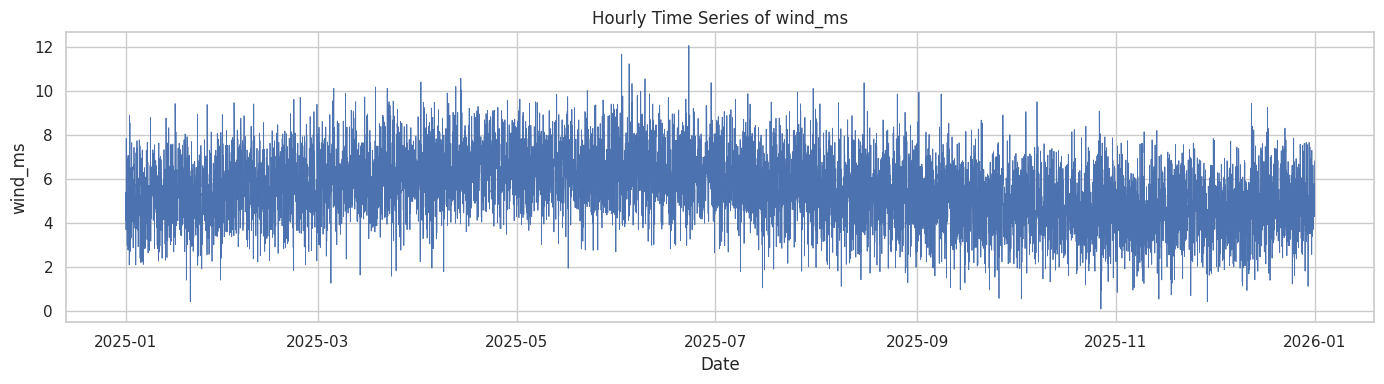


MONTHLY MEAN SIGNIFICANT WAVE HEIGHT


,hs_m
month,
1,1.253970
2,1.555565
3,1.573238
4,1.615544
5,1.732340
6,1.651494
7,1.566386
8,1.407603
9,1.249876


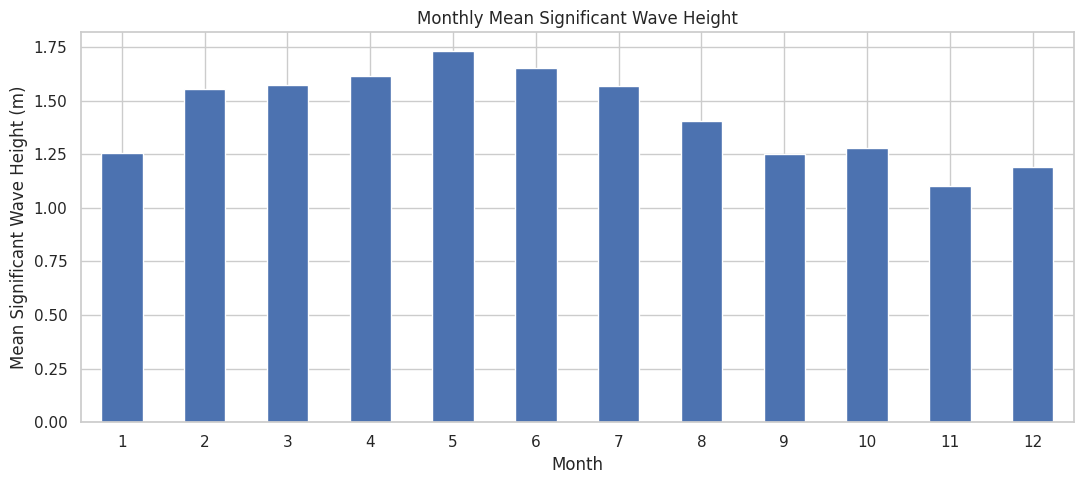

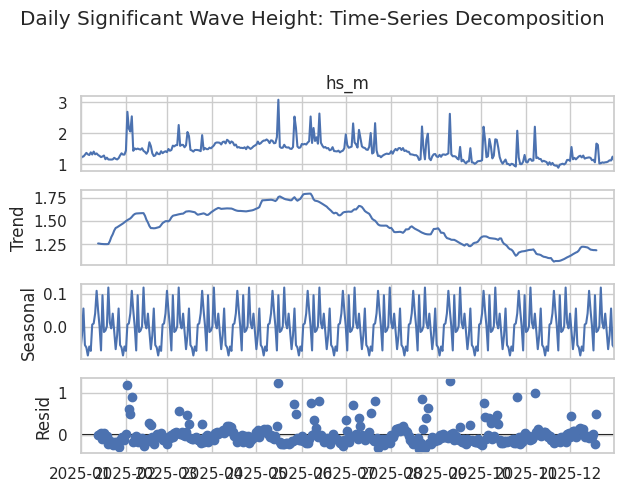


QUESTION 2 ANALYSIS COMPLETED SUCCESSFULLY.


In [ ]:
# ============================================================
# CASE EXERCISE 1: METOCEAN EDA AND SEASONAL ANALYSIS
# QUESTION 2: COMPREHENSIVE EXPLORATORY DATA ANALYSIS
# ============================================================

# STEP 1: IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

# Set the chart appearance
sns.set_theme(style="whitegrid")

# Check that the dataset is available
print("Dataset shape:", df.shape)


# ============================================================
# 2.1 DESCRIPTIVE STATISTICS
# ============================================================

# Select the main metocean variables
metocean_variables = [
    "hs_m",
    "tp_s",
    "current_ms",
    "wind_ms"
]

# Calculate descriptive statistics
descriptive_stats = df[metocean_variables].describe().T

# Add skewness and kurtosis
descriptive_stats["skewness"] = df[metocean_variables].skew()

descriptive_stats["kurtosis"] = df[metocean_variables].kurtosis()

print("\nDESCRIPTIVE STATISTICS")

display(descriptive_stats)


# ============================================================
# 2.2 WEIBULL DISTRIBUTION FIT FOR SIGNIFICANT WAVE HEIGHT
# ============================================================

# Extract significant wave height and remove missing values
hs_data = df["hs_m"].dropna()

# Fit a Weibull distribution
# floc=0 fixes the location parameter at zero
weibull_shape, weibull_location, weibull_scale = (
    stats.weibull_min.fit(hs_data, floc=0)
)

# Perform the Kolmogorov-Smirnov goodness-of-fit test
weibull_ks_stat, weibull_p_value = stats.kstest(
    hs_data,
    "weibull_min",
    args=(weibull_shape, weibull_location, weibull_scale)
)

print("\nWEIBULL DISTRIBUTION RESULTS")

print(f"Shape parameter: {weibull_shape:.4f}")
print(f"Location parameter: {weibull_location:.4f}")
print(f"Scale parameter: {weibull_scale:.4f}")
print(f"KS statistic: {weibull_ks_stat:.4f}")
print(f"KS p-value: {weibull_p_value:.4f}")

if weibull_p_value > 0.05:
    print("Interpretation: The KS test does not reject the Weibull fit at the 5% level.")
else:
    print("Interpretation: The KS test indicates evidence against the Weibull fit at the 5% level.")


# Plot the observed and fitted Weibull distributions
plt.figure(figsize=(10, 6))

sns.histplot(
    hs_data,
    bins=40,
    stat="density",
    color="skyblue",
    label="Observed Hs",
    alpha=0.6
)

x_hs = np.linspace(hs_data.min(), hs_data.max(), 300)

plt.plot(
    x_hs,
    stats.weibull_min.pdf(
        x_hs,
        weibull_shape,
        loc=weibull_location,
        scale=weibull_scale
    ),
    linewidth=2,
    label="Fitted Weibull distribution"
)

plt.title("Weibull Distribution Fit for Significant Wave Height")
plt.xlabel("Significant Wave Height, Hs (m)")
plt.ylabel("Probability Density")
plt.legend()
plt.show()


# ============================================================
# 2.3 LOG-NORMAL DISTRIBUTION FIT FOR PEAK WAVE PERIOD
# ============================================================

# Extract peak wave period and remove missing values
tp_data = df["tp_s"].dropna()

# Fit a log-normal distribution
# floc=0 fixes the location parameter at zero
lognorm_shape, lognorm_location, lognorm_scale = (
    stats.lognorm.fit(tp_data, floc=0)
)

# Perform the Kolmogorov-Smirnov goodness-of-fit test
lognorm_ks_stat, lognorm_p_value = stats.kstest(
    tp_data,
    "lognorm",
    args=(lognorm_shape, lognorm_location, lognorm_scale)
)

print("\nLOG-NORMAL DISTRIBUTION RESULTS")

print(f"Shape parameter: {lognorm_shape:.4f}")
print(f"Location parameter: {lognorm_location:.4f}")
print(f"Scale parameter: {lognorm_scale:.4f}")
print(f"KS statistic: {lognorm_ks_stat:.4f}")
print(f"KS p-value: {lognorm_p_value:.4f}")

if lognorm_p_value > 0.05:
    print("Interpretation: The KS test does not reject the log-normal fit at the 5% level.")
else:
    print("Interpretation: The KS test indicates evidence against the log-normal fit at the 5% level.")


# Plot the observed and fitted log-normal distributions
plt.figure(figsize=(10, 6))

sns.histplot(
    tp_data,
    bins=40,
    stat="density",
    color="lightgreen",
    label="Observed Tp",
    alpha=0.6
)

x_tp = np.linspace(tp_data.min(), tp_data.max(), 300)

plt.plot(
    x_tp,
    stats.lognorm.pdf(
        x_tp,
        lognorm_shape,
        loc=lognorm_location,
        scale=lognorm_scale
    ),
    linewidth=2,
    label="Fitted log-normal distribution"
)

plt.title("Log-Normal Distribution Fit for Peak Wave Period")
plt.xlabel("Peak Wave Period, Tp (s)")
plt.ylabel("Probability Density")
plt.legend()
plt.show()


# ============================================================
# 2.4 CORRELATION MATRIX
# ============================================================

# Use environmental magnitudes for Pearson correlation.
# Direction variables are excluded because angles wrap around
# at 360 degrees and ordinary Pearson correlation can mislead.

correlation_matrix = df[metocean_variables].corr(method="pearson")

print("\nMETOCEAN CORRELATION MATRIX")

display(correlation_matrix)

# Plot the correlation matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix of Metocean Variables")
plt.show()


# ============================================================
# 2.5 TIME-SERIES ANALYSIS
# ============================================================

# Set timestamp as the index for time-series plotting
df_time = df.set_index("timestamp").sort_index()

# Plot each metocean variable over time
for variable in metocean_variables:

    plt.figure(figsize=(14, 4))

    plt.plot(
        df_time.index,
        df_time[variable],
        linewidth=0.6
    )

    plt.title(f"Hourly Time Series of {variable}")
    plt.xlabel("Date")
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()


# ============================================================
# 2.6 MONTHLY SEASONAL ANALYSIS
# ============================================================

# Extract month from timestamp
df["month"] = df["timestamp"].dt.month

# Calculate monthly mean significant wave height
monthly_hs = df.groupby("month")["hs_m"].mean()

print("\nMONTHLY MEAN SIGNIFICANT WAVE HEIGHT")

display(monthly_hs)

# Plot monthly mean wave height
plt.figure(figsize=(11, 5))

monthly_hs.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Monthly Mean Significant Wave Height")
plt.xlabel("Month")
plt.ylabel("Mean Significant Wave Height (m)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 2.7 DAILY SEASONAL DECOMPOSITION OF WAVE HEIGHT
# ============================================================

# Resample the hourly observations to daily mean Hs
daily_hs = df_time["hs_m"].resample("D").mean()

# Decompose using a 24-day period on the daily series.
# This explores a repeating pattern over a 24-day window,
# not the annual seasonal cycle.

decomposition = seasonal_decompose(
    daily_hs,
    model="additive",
    period=24
)

# Plot the decomposition components
decomposition.plot()

plt.suptitle(
    "Daily Significant Wave Height: Time-Series Decomposition",
    y=1.02
)

plt.tight_layout()
plt.show()


# ============================================================
# END OF QUESTION 2
# ============================================================

print("\nQUESTION 2 ANALYSIS COMPLETED SUCCESSFULLY.")

In [ ]:
# Display exact KS test p-values

print("Weibull KS p-value:", f"{weibull_p_value:.10e}")

print("Log-normal KS p-value:", f"{lognorm_p_value:.10e}")

Weibull KS p-value: 4.3163128950e-108
Log-normal KS p-value: 9.5248708944e-03


### Question 2: Results and Engineering Discussion

The exploratory data analysis provided an overview of the statistical characteristics, distributions, correlations and seasonal behaviour of the metocean variables.

The Weibull distribution fitted to significant wave height produced a shape parameter of 3.2039 and a scale parameter of 1.5846 m. However, the KS goodness-of-fit test returned a p-value below 0.05, indicating that the fitted distribution was not statistically supported at the 5% significance level.

Similarly, the log-normal distribution fitted to peak wave period produced a shape parameter of 0.1043 and a scale parameter of 8.8841 seconds. Its KS p-value of 0.0095 also indicated evidence against the fitted distribution at the 5% significance level.

The correlation analysis identified a moderate positive relationship between significant wave height and peak wave period (r = 0.5357). The relationship between significant wave height and current speed was weakly positive (r = 0.1175), while the relationship between wave height and wind speed was also positive but relatively weak (r = 0.2683).

The monthly analysis showed that May had the highest mean significant wave height of approximately 1.732 m, while November had the lowest at approximately 1.101 m.

From an engineering perspective, these findings demonstrate the importance of examining environmental variability and relationships between metocean parameters before conducting extreme wave and fatigue assessments.

The distribution fitting results also demonstrate that commonly used theoretical distributions should be validated against observed data rather than automatically assumed to provide an adequate representation.

**Conclusion:** The EDA established the statistical and seasonal characteristics of the synthetic metocean dataset and provided an initial understanding of the environmental variables that will be investigated further in the extreme value and fatigue analyses.

## Question 3: Hs-Tp Scatter Plot and Current Rose Diagram

### 3.1 Relationship Between Significant Wave Height (Hs) and Peak Wave Period (Tp)

A scatter plot will be used to investigate the relationship between significant wave height (Hs) and peak wave period (Tp).

The plot will help identify patterns, trends and possible relationships between wave height and wave period. A regression line and Pearson correlation coefficient will be used to assess the strength and direction of the linear relationship.

### 3.2 Current Rose Diagram

A current rose diagram will be developed to examine the directional distribution and speed of ocean currents.

The diagram will divide current directions into compass sectors and group current speeds into categories. This will help identify the dominant current directions and the frequency of different current-speed ranges.

### 3.3 Engineering Significance

Understanding the relationship between wave height and wave period is important when characterising sea states and evaluating environmental loading on subsea structures.

Similarly, current direction and speed are important considerations in subsea engineering because ocean currents can contribute to hydrodynamic loading on pipelines, risers and other subsea infrastructure.

The results will provide additional environmental information for subsequent extreme value analysis and metocean-fatigue assessment.

HS-TP RELATIONSHIP
Pearson correlation: 0.5357


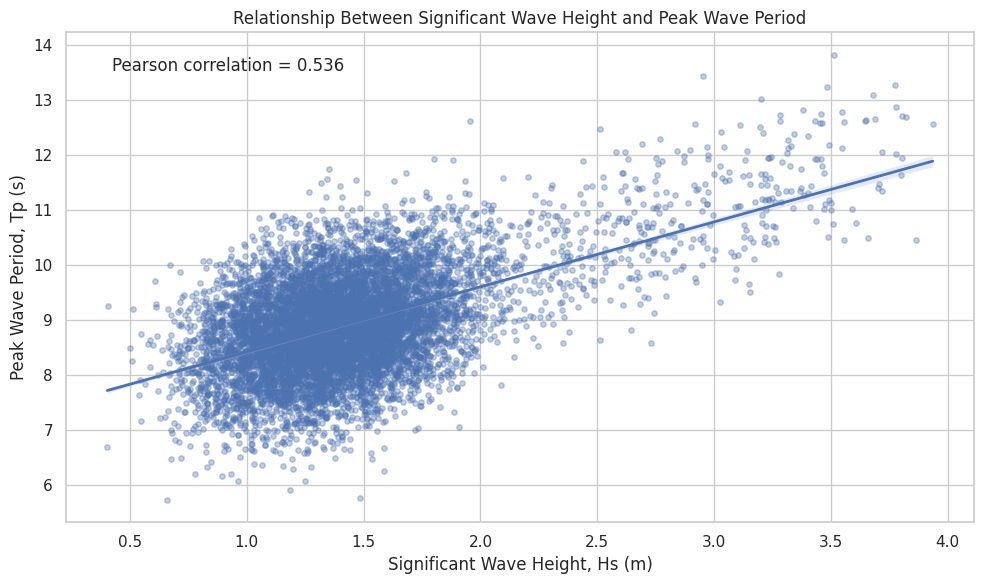

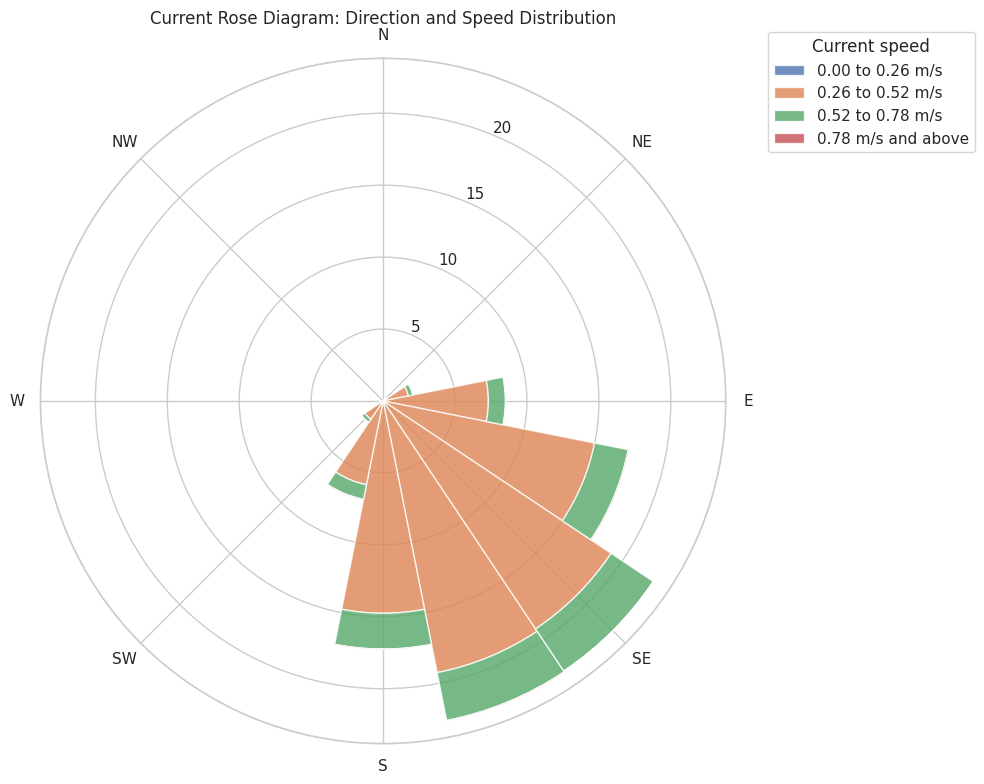


CURRENT SPEED SUMMARY


,current_speed
count,8760.000000
mean,0.437771
std,0.083846
min,0.270000
25%,0.378000
50%,0.429000
75%,0.483250
max,1.040000



MOST FREQUENT CURRENT DIRECTIONS


,Direction,Frequency (%)
7,SSE,22.682648
6,SE,22.591324
5,ESE,17.420091
8,S,17.271689
4,E,8.527397
9,SSW,7.020548
3,ENE,2.111872
10,SW,1.803653
2,NE,0.273973
11,WSW,0.262557



QUESTION 3 COMPLETED SUCCESSFULLY.


In [ ]:
# ============================================================
# CASE EXERCISE 1: METOCEAN EDA AND SEASONAL ANALYSIS
# QUESTION 3: HS-TP SCATTER PLOT AND CURRENT ROSE DIAGRAM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 3.1 HS-TP SCATTER PLOT
# ============================================================

# Select wave height and wave period
wave_data = df[["hs_m", "tp_s"]].dropna()

# Calculate Pearson correlation
correlation = wave_data["hs_m"].corr(wave_data["tp_s"])

print("HS-TP RELATIONSHIP")
print(f"Pearson correlation: {correlation:.4f}")

# Create scatter plot with regression line
plt.figure(figsize=(10, 6))

sns.regplot(
    data=wave_data,
    x="hs_m",
    y="tp_s",
    scatter_kws={"alpha": 0.35, "s": 15},
    line_kws={"linewidth": 2}
)

plt.title("Relationship Between Significant Wave Height and Peak Wave Period")
plt.xlabel("Significant Wave Height, Hs (m)")
plt.ylabel("Peak Wave Period, Tp (s)")

plt.text(
    0.05,
    0.95,
    f"Pearson correlation = {correlation:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()
plt.show()


# ============================================================
# 3.2 CURRENT ROSE DIAGRAM
# ============================================================

# IMPORTANT: Use current_ms because we renamed the column
# in Question 1.

current_data = df[
    ["current_ms", "current_direction_deg"]
].dropna().copy()

# Rename for easier reference
current_data.rename(columns={
    "current_ms": "current_speed",
    "current_direction_deg": "current_direction"
}, inplace=True)

# Keep non-negative current speeds
current_data = current_data[
    current_data["current_speed"] >= 0
].copy()

# Ensure directions are between 0 and 360 degrees
current_data["current_direction"] = (
    current_data["current_direction"] % 360
)

# Define 16 compass direction sectors
number_of_sectors = 16
sector_width = 360 / number_of_sectors

sector_index = np.floor(
    (
        current_data["current_direction"] + sector_width / 2
    ) % 360 / sector_width
).astype(int)

# Define four current-speed categories
maximum_speed = current_data["current_speed"].max()

if maximum_speed <= 0:
    raise ValueError("Current speed contains no positive values.")

speed_edges = np.linspace(0, maximum_speed, 5)
speed_edges[-1] = np.inf

speed_index = np.digitize(
    current_data["current_speed"],
    speed_edges[1:-1]
)

# Count observations by direction and speed category
rose_counts = np.zeros(
    (number_of_sectors, len(speed_edges) - 1)
)

for sector in range(number_of_sectors):

    for speed_category in range(len(speed_edges) - 1):

        rose_counts[sector, speed_category] = np.sum(
            (sector_index == sector) &
            (speed_index == speed_category)
        )

# Convert counts into percentages
rose_percentages = (
    rose_counts / rose_counts.sum()
) * 100

# Calculate sector centre angles
sector_angles = np.deg2rad(
    np.arange(number_of_sectors) * sector_width
)

# Create polar plot
fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"projection": "polar"}
)

# Set North at the top and clockwise direction
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

# Plot stacked current-speed categories
bottom = np.zeros(number_of_sectors)

for i in range(len(speed_edges) - 1):

    ax.bar(
        sector_angles,
        rose_percentages[:, i],
        width=np.deg2rad(sector_width),
        bottom=bottom,
        alpha=0.8,
        label=(
            f"{speed_edges[i]:.2f} to "
            f"{speed_edges[i + 1]:.2f} m/s"
            if np.isfinite(speed_edges[i + 1])
            else f"{speed_edges[i]:.2f} m/s and above"
        )
    )

    bottom += rose_percentages[:, i]

# Add chart labels
ax.set_title(
    "Current Rose Diagram: Direction and Speed Distribution",
    pad=25
)

ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))

ax.set_xticklabels([
    "N", "NE", "E", "SE",
    "S", "SW", "W", "NW"
])

ax.legend(
    title="Current speed",
    loc="upper left",
    bbox_to_anchor=(1.05, 1.05)
)

plt.tight_layout()
plt.show()


# ============================================================
# 3.3 CURRENT SPEED AND DIRECTION SUMMARY
# ============================================================

print("\nCURRENT SPEED SUMMARY")

display(current_data["current_speed"].describe())

# Calculate direction frequencies
sector_labels = [
    "N", "NNE", "NE", "ENE",
    "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW",
    "W", "WNW", "NW", "NNW"
]

direction_summary = pd.DataFrame({
    "Direction": sector_labels,
    "Frequency (%)": rose_percentages.sum(axis=1)
})

direction_summary = direction_summary.sort_values(
    by="Frequency (%)",
    ascending=False
)

print("\nMOST FREQUENT CURRENT DIRECTIONS")

display(direction_summary)

print("\nQUESTION 3 COMPLETED SUCCESSFULLY.")

## Question 4: Temporal, Seasonal, Rolling and Cumulative Feature Engineering

### 4.1 Temporal Features

Temporal features will be extracted from the timestamp column to identify patterns associated with different times of the day, days of the week and months of the year.

The features will include hour, day, month, day of the week and day of the year.

### 4.2 Seasonal Features

Seasonal features will be developed to represent variations in the Gulf of Guinea metocean environment.

The analysis will distinguish between the relatively calmer dry season (November to March) and the more energetic wet/storm season (April to October).

Cyclical encoding using sine and cosine transformations will also be applied to month and hour values. This allows the model to recognise the cyclical nature of time, such as the relationship between December and January.

### 4.3 Rolling Statistical Features

Rolling statistics will be calculated over 6-hour, 24-hour, 168-hour and 720-hour windows.

For significant wave height, peak wave period, current speed and wind speed, the rolling mean, standard deviation, maximum, minimum and range will be calculated.

These features will help capture short-term and longer-term environmental variability.

### 4.4 Cumulative Environmental Exposure Features

Cumulative features will be generated to represent the accumulated environmental exposure experienced over time.

These will include cumulative severe-wave hours, cumulative wave energy proxy and hours since the last calm condition.

A severe-wave condition will be identified when significant wave height exceeds 2.0 m, while a calm condition will be identified when significant wave height is below 1.0 m.

### 4.5 Engineering Significance

Temporal and seasonal features help identify recurring environmental patterns, while rolling statistics capture changing sea-state conditions.

Cumulative features provide information about the environmental exposure experienced over time.

These engineered variables will form an enriched metocean dataset for subsequent extreme value analysis and fatigue correlation modelling.

In [ ]:
# ============================================================
# CASE EXERCISE 1: METOCEAN EDA AND SEASONAL ANALYSIS
# QUESTION 4: FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np
import os

# ============================================================
# STEP 1: PREPARE THE DATASET
# ============================================================

# Create a separate copy of the original dataset
df_features = df.copy()

# Ensure timestamp is in datetime format
df_features["timestamp"] = pd.to_datetime(
    df_features["timestamp"]
)

# Sort observations chronologically
df_features = df_features.sort_values(
    "timestamp"
).reset_index(drop=True)

# Define the metocean variables
metocean_variables = [
    "hs_m",
    "tp_s",
    "current_ms",
    "wind_ms"
]

print("Original dataset shape:", df_features.shape)


# ============================================================
# 4.1 TEMPORAL FEATURES
# ============================================================

# Extract time-based information
df_features["hour"] = df_features["timestamp"].dt.hour

df_features["day"] = df_features["timestamp"].dt.day

df_features["month"] = df_features["timestamp"].dt.month

df_features["day_of_week"] = (
    df_features["timestamp"].dt.dayofweek
)

df_features["day_of_year"] = (
    df_features["timestamp"].dt.dayofyear
)

df_features["week_of_year"] = (
    df_features["timestamp"].dt.isocalendar().week.astype(int)
)

# Identify weekends
df_features["is_weekend"] = (
    df_features["day_of_week"] >= 5
).astype(int)


# ============================================================
# 4.2 SEASONAL FEATURES
# ============================================================

# Define Gulf of Guinea seasonal categories
# Dry season: November to March
# Wet/storm season: April to October

df_features["season"] = np.where(
    df_features["month"].isin([11, 12, 1, 2, 3]),
    "Dry",
    "Wet"
)

# Convert season into a numerical variable
df_features["season_encoded"] = (
    df_features["season"].map({
        "Dry": 0,
        "Wet": 1
    })
)

# Cyclical encoding for month
df_features["month_sin"] = np.sin(
    2 * np.pi * df_features["month"] / 12
)

df_features["month_cos"] = np.cos(
    2 * np.pi * df_features["month"] / 12
)

# Cyclical encoding for hour
df_features["hour_sin"] = np.sin(
    2 * np.pi * df_features["hour"] / 24
)

df_features["hour_cos"] = np.cos(
    2 * np.pi * df_features["hour"] / 24
)


# ============================================================
# 4.3 ROLLING STATISTICAL FEATURES
# ============================================================

# Define rolling windows in hours
rolling_windows = [6, 24, 168, 720]

# Calculate rolling statistics for each metocean variable
for variable in metocean_variables:

    for window in rolling_windows:

        rolling = df_features[variable].rolling(
            window=window,
            min_periods=1
        )

        # Rolling mean
        df_features[
            f"{variable}_rolling_mean_{window}h"
        ] = rolling.mean()

        # Rolling standard deviation
        df_features[
            f"{variable}_rolling_std_{window}h"
        ] = rolling.std()

        # Rolling maximum
        df_features[
            f"{variable}_rolling_max_{window}h"
        ] = rolling.max()

        # Rolling minimum
        df_features[
            f"{variable}_rolling_min_{window}h"
        ] = rolling.min()

        # Rolling range
        df_features[
            f"{variable}_rolling_range_{window}h"
        ] = (
            df_features[
                f"{variable}_rolling_max_{window}h"
            ]
            -
            df_features[
                f"{variable}_rolling_min_{window}h"
            ]
        )


# ============================================================
# 4.4 CUMULATIVE ENVIRONMENTAL EXPOSURE FEATURES
# ============================================================

# Identify severe wave conditions
df_features["severe_flag"] = (
    df_features["hs_m"] > 2.0
).astype(int)

# Calculate cumulative hours with severe wave conditions
df_features["cum_severe_hours"] = (
    df_features["severe_flag"].cumsum()
)

# Calculate squared significant wave height
df_features["hs_squared"] = (
    df_features["hs_m"] ** 2
)

# Calculate cumulative wave energy proxy
df_features["cum_wave_energy"] = (
    df_features["hs_squared"].cumsum()
)

# Identify calm conditions
calm_flag = df_features["hs_m"] < 1.0

# Calculate hours since the most recent calm condition
df_features["hours_since_calm"] = (
    (~calm_flag)
    .groupby(calm_flag.cumsum())
    .cumsum()
)


# ============================================================
# 4.5 ADDITIONAL ENVIRONMENTAL FEATURES
# ============================================================

# Calculate wave steepness proxy
# Wave length approximation using deep-water dispersion
g = 9.81

wave_length = (
    g * df_features["tp_s"] ** 2
) / (2 * np.pi)

df_features["wave_steepness"] = (
    df_features["hs_m"] / wave_length
)

# Calculate a wave energy proxy
df_features["wave_energy_proxy"] = (
    df_features["hs_m"] ** 2
)

# Calculate a combined wind and wave loading proxy
df_features["wind_wave_proxy"] = (
    df_features["hs_m"] * df_features["wind_ms"]
)


# ============================================================
# 4.6 CHECK THE ENRICHED DATASET
# ============================================================

print("\nENRICHED DATASET INFORMATION")

print("Original number of columns:", df.shape[1])

print("Enriched number of columns:", df_features.shape[1])

print(
    "Number of new features:",
    df_features.shape[1] - df.shape[1]
)

print("\nFIRST FIVE ROWS OF ENRICHED DATASET")

display(df_features.head())

print("\nENRICHED DATASET SUMMARY")

display(df_features.describe())


# ============================================================
# 4.7 CHECK MISSING VALUES
# ============================================================

print("\nMISSING VALUES IN ENRICHED DATASET")

display(
    df_features.isnull().sum()[
        df_features.isnull().sum() > 0
    ]
)


# ============================================================
# 4.8 SAVE THE ENRICHED DATASET
# ============================================================

# Create the output directory
os.makedirs(
    "outputs/processed_data",
    exist_ok=True
)

# Save the enriched dataset
output_path = (
    "outputs/processed_data/"
    "jubilee_trp3_enriched_metocean.csv"
)

df_features.to_csv(
    output_path,
    index=False
)

print("\nENRICHED DATASET SAVED SUCCESSFULLY")

print("File location:", output_path)

print("\nQUESTION 4 COMPLETED SUCCESSFULLY.")

Original dataset shape: (8760, 9)

ENRICHED DATASET INFORMATION
Original number of columns: 9
Enriched number of columns: 109
Number of new features: 100

FIRST FIVE ROWS OF ENRICHED DATASET


/tmp/ipykernel_1609/3496242951.py:206: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features["wave_steepness"] = (
/tmp/ipykernel_1609/3496242951.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features["wave_energy_proxy"] = (
/tmp/ipykernel_1609/3496242951.py:216: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `ne

,timestamp,hs_m,tp_s,wave_direction_deg,current_ms,current_direction_deg,wind_ms,wind_direction_deg,month,hour,...,wind_ms_rolling_min_720h,wind_ms_rolling_range_720h,severe_flag,cum_severe_hours,hs_squared,cum_wave_energy,hours_since_calm,wave_steepness,wave_energy_proxy,wind_wave_proxy
0,2025-01-01 00:00:00,1.151,9.506,253.8,0.460,190.5,3.711,233.9,1,0,...,3.711,0.000,0,0,1.324801,1.324801,1,0.008158,1.324801,4.271361
1,2025-01-01 01:00:00,1.005,9.678,231.1,0.449,145.6,5.389,209.8,1,1,...,3.711,1.678,0,0,1.010025,2.334826,2,0.006872,1.010025,5.415945
2,2025-01-01 02:00:00,1.308,9.942,179.3,0.484,134.7,4.649,249.9,1,2,...,3.711,1.678,0,0,1.710864,4.045690,3,0.008476,1.710864,6.080892
3,2025-01-01 03:00:00,1.136,8.768,214.8,0.384,137.0,4.122,192.5,1,3,...,3.711,1.678,0,0,1.290496,5.336186,4,0.009464,1.290496,4.682592
4,2025-01-01 04:00:00,1.222,7.180,174.9,0.462,159.9,7.837,214.7,1,4,...,3.711,4.126,0,0,1.493284,6.829470,5,0.015182,1.493284,9.576814



ENRICHED DATASET SUMMARY


,timestamp,hs_m,tp_s,wave_direction_deg,current_ms,current_direction_deg,wind_ms,wind_direction_deg,month,hour,...,wind_ms_rolling_min_720h,wind_ms_rolling_range_720h,severe_flag,cum_severe_hours,hs_squared,cum_wave_energy,hours_since_calm,wave_steepness,wave_energy_proxy,wind_wave_proxy
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,...,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,2025-07-02 11:30:00,1.430837,8.932695,225.933904,0.437771,145.059030,5.512968,210.410068,6.526027,11.500000,...,1.220764,8.825964,0.061073,277.293265,2.228750,10609.408735,327.769064,0.011524,2.228750,8.068473
min,2025-01-01 00:00:00,0.403000,5.724000,104.300000,0.270000,19.800000,0.100000,2.900000,1.000000,0.000000,...,0.100000,0.000000,0.000000,0.000000,0.162409,1.324801,0.000000,0.003026,0.162409,0.139400
25%,2025-04-02 05:45:00,1.166000,8.312750,204.300000,0.378000,119.800000,4.451750,182.100000,4.000000,5.750000,...,0.552000,8.769000,0.000000,117.000000,1.359556,4976.232190,3.000000,0.009483,1.359556,5.410086
50%,2025-07-02 11:30:00,1.378500,8.886500,225.400000,0.429000,145.300000,5.482500,210.500000,7.000000,11.500000,...,1.133000,8.982000,0.000000,290.000000,1.900262,11382.259984,26.000000,0.011279,1.900262,7.509821
75%,2025-10-01 17:15:00,1.602250,9.484000,247.900000,0.483250,170.125000,6.598000,238.800000,10.000000,17.250000,...,1.796000,9.231000,0.000000,423.000000,2.567205,16085.718053,317.000000,0.013269,2.567205,10.039907
max,2025-12-31 23:00:00,3.936000,13.834000,346.300000,1.040000,273.900000,12.054000,356.700000,12.000000,23.000000,...,3.711000,10.993000,1.000000,535.000000,15.492096,19523.852662,2253.000000,0.028609,15.492096,34.301168
std,NaN,0.426001,0.939776,32.011619,0.083846,34.661562,1.577789,41.193361,3.448048,6.922582,...,0.765227,0.798758,0.239478,176.684694,1.604879,6103.123684,580.141954,0.002836,1.604879,3.824838



MISSING VALUES IN ENRICHED DATASET


,0
hs_m_rolling_std_6h,1
hs_m_rolling_std_24h,1
hs_m_rolling_std_168h,1
hs_m_rolling_std_720h,1
tp_s_rolling_std_6h,1
tp_s_rolling_std_24h,1
tp_s_rolling_std_168h,1
tp_s_rolling_std_720h,1
current_ms_rolling_std_6h,1
current_ms_rolling_std_24h,1



ENRICHED DATASET SAVED SUCCESSFULLY
File location: outputs/processed_data/jubilee_trp3_enriched_metocean.csv

QUESTION 4 COMPLETED SUCCESSFULLY.


In [ ]:
from google.colab import files

files.download(
    "outputs/processed_data/jubilee_trp3_enriched_metocean.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>